In [28]:
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

In [29]:
import os
import subprocess
from pathlib import Path

import anndata as ad
import colorcet as cc
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

from batch_integration.multisample_utils import preprocess_genes, preprocess_scaling
from utils import (
    DATA_DIR,
    RESULT_DIR,
    SHELL,
    activate_env_cmd,
    mm,
    rc_params,
    remove_tick_and_label,
)

mpl.rcParams.update(rc_params)

In [30]:
# Settings
seed = 42

SINGLE_DIR = "single_sample"
PATIENT_DIR = "patient"
ALL_DIR = "all"

libd_dlpfc_dir = DATA_DIR / "LIBD_DLPFC"
libd_dlpfc_results = RESULT_DIR / "LIBD_DLPFC"

In [31]:
env = os.environ.copy()
env["MPLBACKEND"] = "pdf"  # avoid matplotlib backend issues

In [32]:
conda_cmd = activate_env_cmd("spatialleiden")  # define conda env to run scripts in

In [6]:
adata = ad.read_h5ad(libd_dlpfc_dir / "raw.h5ad")

del adata.obsm
del adata.uns
del adata.layers

adata.obsm["spatial"] = adata.obs[["x", "y"]].to_numpy().astype(int)

adata.var = adata.var[["gene_name", "type", "gene_biotype"]]

adata.obs = adata.obs[["sample_id", "subject", "discard", "spatialLIBD"]].rename(
    columns={"spatialLIBD": "label"}
)

adata.X = adata.X.tocsr().astype("int32")

/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/spatialleiden/lib/python3.12/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


# Preprocess

In [7]:
# whether to center data for scaling and PCA
center = True

## Single sample

In [8]:
out_dir = libd_dlpfc_dir / SINGLE_DIR
out_dir.mkdir(exist_ok=True, parents=True)

for patient_sample, idx in adata.obs.groupby(
    ["subject", "sample_id"], observed=True
).indices.items():
    sample = "_".join(patient_sample)
    adata_sample = adata[idx, :].copy()
    adata_sample.uns["n_clusters"] = adata_sample.obs["label"].nunique()

    preprocess_genes(adata_sample, batch_key=None)
    preprocess_scaling(adata_sample, center=center, seed=seed)

    adata_sample.write(out_dir / f"{sample}.h5ad")

## Patient-wise

In [9]:
out_dir = libd_dlpfc_dir / PATIENT_DIR
out_dir.mkdir(exist_ok=True, parents=True)

for patient, idx in adata.obs.groupby("subject", observed=True).indices.items():
    adata_patient = adata[idx, :].copy()
    adata_patient.uns["n_clusters"] = adata_patient.obs["label"].nunique()
    adata_patient.uns["batch_keys"] = ["sample_id"]
    adata_patient.obs_names_make_unique()

    preprocess_genes(adata_patient, batch_key=None)
    preprocess_scaling(adata_patient, center=center, seed=seed)

    adata_patient.write(out_dir / f"{patient}.h5ad")

/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/spatialleiden/lib/python3.12/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/spatialleiden/lib/python3.12/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/spatialleiden/lib/python3.12/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


## All

In [10]:
out_dir = libd_dlpfc_dir / ALL_DIR
out_dir.mkdir(exist_ok=True, parents=True)

adata.obs_names_make_unique()
adata.uns["n_clusters"] = adata.obs["label"].nunique()
adata.uns["batch_keys"] = ["sample_id", "subject"]

preprocess_genes(adata, batch_key=adata.uns["batch_keys"][0])
preprocess_scaling(adata, center=center, seed=seed)

adata.write(out_dir / "LIBD_DLPFC.h5ad")

# Batch integration

In [11]:
script_dir = Path("batch_integration")

## Single sample (i.e. no integration)

In [12]:
file_dir = libd_dlpfc_dir / SINGLE_DIR
script_path = script_dir / "no_batch_integration.py"

for h5ad in file_dir.glob("*.h5ad"):
    name = h5ad.stem
    out_dir = libd_dlpfc_results / h5ad.parent.name
    out_dir.mkdir(exist_ok=True, parents=True)
    out_file = out_dir / f"{name}.npz"

    cmd = f"{script_path} {h5ad} {out_file}"

    subprocess.run(f"{conda_cmd} && {cmd}", shell=True, executable=SHELL, env=env)

## Patient-wise / All

In [13]:
methods = [
    "no_batch_integration",
    "bbknn",
    "harmony",
    "scvi",
    "scanorama",
]

In [14]:
files = list((libd_dlpfc_dir / PATIENT_DIR).glob("*.h5ad")) + list(
    (libd_dlpfc_dir / ALL_DIR).glob("*.h5ad")
)

In [15]:
for h5ad in files:
    name = h5ad.stem

    for method in methods:
        # scvi is incompatible with the rest of the environment
        if method == "scvi":
            conda_cmd = activate_env_cmd("scvi")
        else:
            conda_cmd = activate_env_cmd("spatialleiden")

        out_dir = libd_dlpfc_results / method / h5ad.parent.name
        out_dir.mkdir(exist_ok=True, parents=True)
        out_file = out_dir / f"{name}.npz"

        script_path = script_dir / f"{method}.py"

        cmd = f"{script_path} {h5ad} {out_file}"

        # because bbknn uses n neighbors per batch we decrease the number of neighbors
        # so its roughly equal to the rest
        if method == "bbknn":
            n = 5  # change based on within or across patients?
            cmd += f" --n_neighs {n}"
        elif method == "scvi":
            n_comp = 20
            cmd += f" --n_comp {n_comp}"

        subprocess.run(f"{conda_cmd} && {cmd}", shell=True, executable=SHELL, env=env)

2026-02-05 22:19:35,712 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-02-05 22:19:35,712 - harmonypy - INFO -   Parameters:
2026-02-05 22:19:35,712 - harmonypy - INFO -     max_iter_harmony: 10
2026-02-05 22:19:35,712 - harmonypy - INFO -     max_iter_kmeans: 20
2026-02-05 22:19:35,712 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-02-05 22:19:35,712 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-02-05 22:19:35,712 - harmonypy - INFO -     nclust: 100
2026-02-05 22:19:35,713 - harmonypy - INFO -     block_size: 0.05
2026-02-05 22:19:35,713 - harmonypy - INFO -     lamb: [1. 1. 1. 1.]
2026-02-05 22:19:35,713 - harmonypy - INFO -     theta: [2. 2. 2. 2.]
2026-02-05 22:19:35,713 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-02-05 22:19:35,713 - harmonypy - INFO -     verbose: True
2026-02-05 22:19:35,713 - harmonypy - INFO -     random_state: 42
2026-02-05 22:19:35,713 - harmonypy - INFO -   Data: 30 PCs × 18033 cells
2026-02-05 22:19:35,713 - ha

# Clustering

In [16]:
script_dir = Path("clustering")
script_path = script_dir / "spatialleiden_multisample.py"

conda_cmd = activate_env_cmd("spatialleiden")

layer_ratio = 0.8

## Single sample

In [17]:
file_dir = libd_dlpfc_dir / SINGLE_DIR

for h5ad in file_dir.glob("*.h5ad"):
    name = h5ad.stem
    out_dir = libd_dlpfc_results / h5ad.parent.name
    neighbor_file = out_dir / f"{name}.npz"
    out_file = out_dir / f"{name}.parquet"

    cmd = f"{script_path} {h5ad} {neighbor_file} {out_file}"
    cmd += f" --weight {layer_ratio}"
    cmd += " --coord_type grid"

    subprocess.run(f"{conda_cmd} && {cmd}", shell=True, executable=SHELL, env=env)

/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/spatialleiden/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/spatialleiden/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/

## Patient-wise / All

In [18]:
for file in libd_dlpfc_results.glob("*/*/*.npz"):
    name = file.stem
    batch = file.parent.name
    method = file.parents[1].name

    h5ad = libd_dlpfc_dir / batch / f"{name}.h5ad"
    out_file = file.parent / f"{name}.parquet"

    cmd = f"{script_path} {h5ad} {file} {out_file}"
    # bbknn has different number of neighbors therefore different weight is required
    # increase spatial weight to counteract increase #neighbors in latent space
    if method != "bbknn":
        cmd += f" --weight {layer_ratio}"
    else:
        cmd += " --weight 1.2"
    cmd += " --coord_type grid"
    cmd += " --use_batch"

    subprocess.run(f"{conda_cmd} && {cmd}", shell=True, executable=SHELL, env=env)

/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/spatialleiden/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/spatialleiden/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/

# Evaluation

In [70]:
integration = {
    "no_batch_integration": "none",
    "bbknn": "BBKNN",
    "harmony": "Harmony",
    "scvi": "scVI",
    "scanorama": "Scanorama",
}

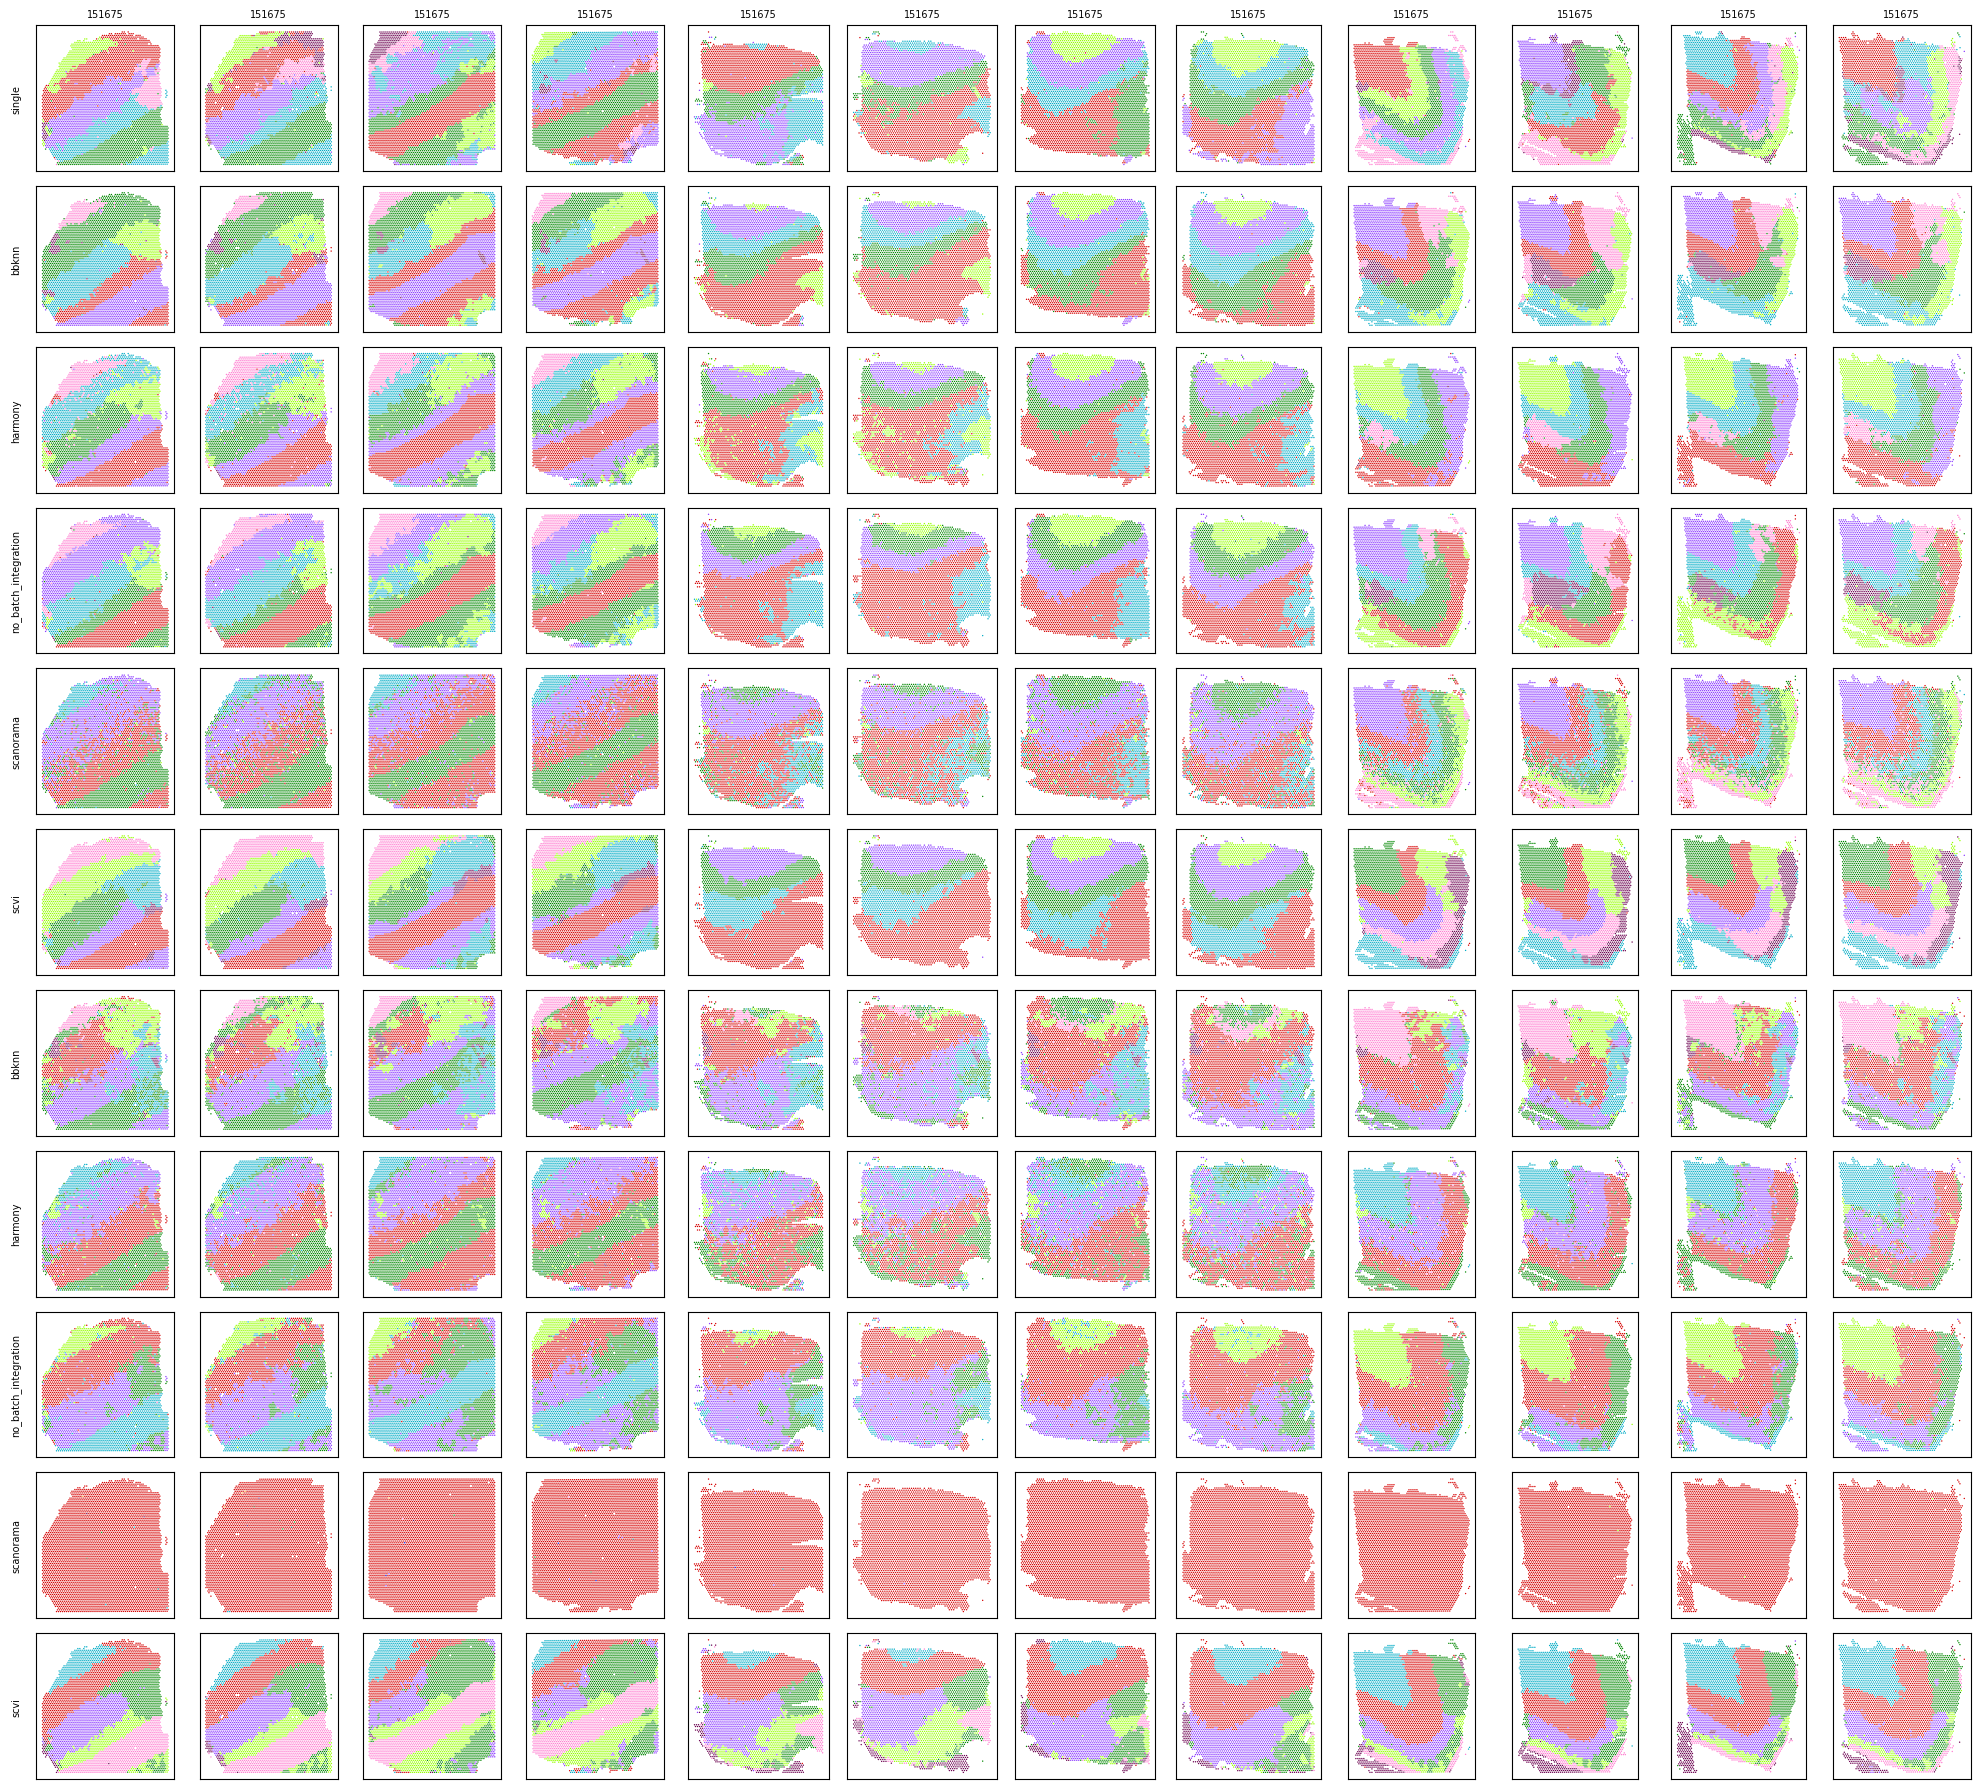

In [71]:
scatter_kwargs = dict(
    s=1,
    linewidth=0,
    x="x",
    y="y",
    hue="spatialleiden",
    legend=False,
    palette=cc.glasbey,
)


with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    fig, axs = plt.subplots(nrows=11, ncols=12, figsize=(20, 18))

    # single sample
    labels = []
    for file in libd_dlpfc_results.glob("*/*.parquet"):
        patient, sample = file.stem.split("_")
        labels.append(pd.read_parquet(file).assign(patient=patient, sample=sample))
    labels = pd.concat(labels).astype(
        {"patient": "category", "spatialleiden": "category", "sample": "category"}
    )

    i = 0
    for p, p_df in labels.groupby("patient", observed=True):
        for s, df in p_df.groupby("sample", observed=True):
            ax = axs[0, i]
            sns.scatterplot(data=df, ax=ax, **scatter_kwargs)
            remove_tick_and_label(ax)
            ax.set(aspect=1, title=sample)
            if i == 0:
                ax.set(ylabel="single")
            i += 1

    # patient-wise
    labels = []
    for file in libd_dlpfc_results.glob("*/patient/*.parquet"):
        tool = file.parents[1].name
        patient = file.stem
        labels.append(pd.read_parquet(file).assign(patient=patient, tool=tool))
    labels = (
        pd.concat(labels)
        .rename(columns={"sample_id": "sample"})
        .astype(
            {"patient": "category", "spatialleiden": "category", "sample": "category"}
        )
    )

    i = 1
    for t, t_df in labels.groupby("tool", observed=True):
        j = 0
        for p, p_df in t_df.groupby("patient", observed=True):
            for s, df in p_df.groupby("sample", observed=True):
                ax = axs[i, j]
                sns.scatterplot(data=df, ax=ax, **scatter_kwargs)
                remove_tick_and_label(ax)
                ax.set(aspect=1)
                if j == 0:
                    ax.set(ylabel=t)
                j += 1
        i += 1

    # all
    labels = []
    for file in libd_dlpfc_results.glob("*/all/*.parquet"):
        tool = file.parents[1].name
        labels.append(pd.read_parquet(file).assign(tool=tool))
    labels = (
        pd.concat(labels)
        .rename(columns={"subject": "patient", "sample_id": "sample"})
        .astype(
            {"patient": "category", "spatialleiden": "category", "sample": "category"}
        )
    )

    for t, t_df in labels.groupby("tool", observed=True):
        j = 0
        for p, p_df in t_df.groupby("patient", observed=True):
            for s, df in p_df.groupby("sample", observed=True):
                ax = axs[i, j]
                sns.scatterplot(data=df, ax=ax, **scatter_kwargs)
                remove_tick_and_label(ax)
                ax.set(aspect=1)
                if j == 0:
                    ax.set(ylabel=t)
                j += 1
        i += 1


fig.tight_layout()

In [72]:
def get_metric(func, metric_name: str):
    metrics = list()

    for file in libd_dlpfc_results.glob("*/*/*.parquet"):
        tool = file.parents[1].name
        batch = file.parent.name
        name = file.stem
        labels = pd.read_parquet(file).astype({"spatialleiden": "category"})
        grouping = [x for x in ["subject", "sample_id"] if x in labels.columns]

        for g, df in labels.groupby(grouping, observed=True):
            sample = g[1] if len(g) > 1 else g[0]
            patient = g[0] if len(g) > 1 else name
            metric = func(df["label"].cat.codes, df["spatialleiden"].cat.codes)
            metrics.append(
                {
                    metric_name: metric,
                    "sample": sample,
                    "patient": patient,
                    "clustering": batch,
                    "tool": tool,
                }
            )

    for file in libd_dlpfc_results.glob("*/*.parquet"):
        patient, sample = file.stem.split("_")
        labels = pd.read_parquet(file, columns=["label", "spatialleiden"]).astype(
            "category"
        )
        metric = func(labels["label"].cat.codes, labels["spatialleiden"].cat.codes)
        metrics.append(
            {
                metric_name: metric,
                "sample": sample,
                "clustering": "sample",
                "tool": "no_batch_integration",
                "patient": patient,
            }
        )

    metrics = pd.DataFrame(metrics).assign(
        tool=lambda df: df["tool"].replace(integration),
        clustering=lambda df: (
            df["clustering"]
            .astype("category")
            .cat.reorder_categories(["sample", "patient", "all"])
        ),
    )

    return metrics

In [73]:
ari_df = get_metric(adjusted_rand_score, "ARI")
nmi_df = get_metric(normalized_mutual_info_score, "NMI")

In [74]:
def custom_swarm(data, **kwargs):
    order = [i for i in integration.values() if i in data[kwargs["x"]].unique()]
    sns.swarmplot(data=data, order=order, **kwargs)

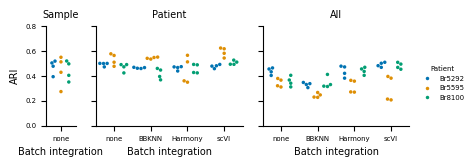

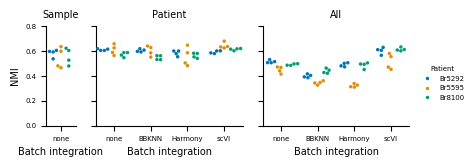

In [75]:
for name, df in {"ARI": ari_df, "NMI": nmi_df}.items():
    df = df.loc[lambda df: df["tool"] != "Scanorama"].assign(
        clustering=lambda df: df["clustering"].cat.rename_categories(
            ari_df["clustering"].cat.categories.str.capitalize()
        )
    )

    g = sns.FacetGrid(
        data=df,
        sharex=False,
        col="clustering",
        height=45 * mm,
        aspect=0.8,
        gridspec_kws={"width_ratios": [1, 5, 5]},
    )
    g.map_dataframe(
        custom_swarm,
        x="tool",
        y=name,
        hue="patient",
        palette="colorblind",
        dodge=True,
        s=2.5,
    )
    _ = g.add_legend(title="Patient")
    _ = g.set(ylim=(0, 0.8), xlabel="Batch integration")
    _ = g.set_titles(col_template="{col_name}")
    g.savefig(libd_dlpfc_results / f"{name}.pdf")

In [47]:
patient = "Br8100"
tool = "scvi"

In [64]:
scatter_kwargs = dict(s=0.5, linewidth=0, x="x", y="y", legend=False)

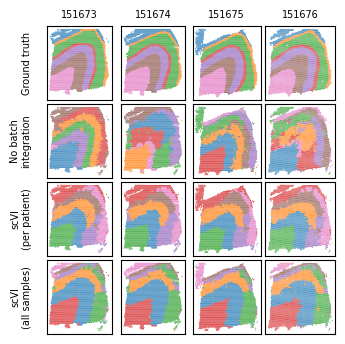

In [65]:
fig, axs = plt.subplots(
    nrows=4, ncols=4, sharey="col", sharex="col", figsize=(90 * mm, 90 * mm)
)

# single sample
labels = []
for file in libd_dlpfc_results.glob(f"*/{patient}*.parquet"):
    _, sample = file.stem.split("_")
    labels.append(pd.read_parquet(file).assign(sample=sample))
labels = pd.concat(labels).astype({"spatialleiden": "category", "sample": "category"})

for j, hue in enumerate(["label", "spatialleiden"]):
    i = 0
    for s, df in labels.groupby("sample", observed=True):
        ax = axs[j, i]
        sns.scatterplot(data=df, hue=hue, ax=ax, **scatter_kwargs)
        if j == 0:
            ax.set(title=s)
        if i == 0:
            ax.set(ylabel=hue)
        i += 1

# patient-wise
labels = (
    pd.read_parquet(libd_dlpfc_results / f"{tool}/patient/{patient}.parquet")
    .assign(tool=tool)
    .rename(columns={"sample_id": "sample"})
    .astype({"spatialleiden": "category", "sample": "category"})
)

j = 2
i = 0
for s, df in labels.groupby("sample", observed=True):
    ax = axs[j, i]
    sns.scatterplot(data=df, hue="spatialleiden", ax=ax, **scatter_kwargs)
    if i == 0:
        ax.set(ylabel=f"{tool} - patient-wise")
    i += 1

# all
labels = (
    pd.read_parquet(libd_dlpfc_results / f"{tool}/all/LIBD_DLPFC.parquet")
    .rename(columns={"subject": "patient", "sample_id": "sample"})
    .loc[lambda df: df["patient"] == patient]
    .astype({"spatialleiden": "category", "sample": "category"})
)

j = 3
i = 0
for s, df in labels.groupby("sample", observed=True):
    ax = axs[j, i]
    sns.scatterplot(data=df, hue="spatialleiden", ax=ax, **scatter_kwargs)
    if i == 0:
        ax.set(ylabel=f"{tool} - all samples")
    i += 1

for ax in axs.flat:
    ax.set(aspect=1)
    remove_tick_and_label(ax)
    ax.yaxis.set_inverted(True)

axs[0, 0].set(ylabel="Ground truth")
axs[1, 0].set(ylabel="No batch\nintegration")
axs[2, 0].set(ylabel="scVI\n(per patient)")
axs[3, 0].set(ylabel="scVI\n(all samples)")

fig.tight_layout()
fig.subplots_adjust(wspace=0.05, hspace=0.05)
fig.savefig(libd_dlpfc_results / f"{patient}_{tool}.pdf")